In [ ]:

import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

import random
import time
import copy
import pandas as pd

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
Device: cuda
GPU: Tesla T4


In [ ]:

from torchvision.datasets import OxfordIIITPet

dataset = OxfordIIITPet(
    root="/content/pet_data",
    split="trainval",
    target_types="category",
    download=True
)

print("Total images:", len(dataset))
print("Total classes:", len(dataset.classes))
print("\nAvailable breeds:")

for i, breed in enumerate(dataset.classes):
    print(i, breed)


100%|██████████| 792M/792M [00:38<00:00, 20.6MB/s]


In [ ]:

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for i, ax in enumerate(axes.flat):
    image, label = dataset[i]
    ax.imshow(image)
    ax.set_title(dataset.classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

shown_breeds = set()
count = 0

for image, label in dataset:
    breed = dataset.classes[label]

    if breed not in shown_breeds:
        ax = axes.flat[count]
        ax.imshow(image)
        ax.set_title(breed)
        ax.axis("off")

        shown_breeds.add(breed)
        count += 1

    if count == 12:
        break

plt.tight_layout()
plt.show()


In [ ]:

# Choose five breeds for our first experiment
selected_breeds = [
    "Abyssinian",
    "Bengal",
    "Persian",
    "Pug",
    "Siamese"
]

# Map each breed to its original dataset label
class_to_idx = {
    breed: dataset.classes.index(breed)
    for breed in selected_breeds
}

print("Selected breeds:")
for breed, label in class_to_idx.items():
    print(f"{breed}: {label}")


In [ ]:

# Keep only our selected breeds and assign labels from 0 to 4
selected_data = []

for i in range(len(dataset)):
    image, label = dataset[i]

    if label in class_to_idx.values():
        new_label = selected_breeds.index(dataset.classes[label])
        selected_data.append((image, new_label))

print("Total selected images:", len(selected_data))
print("Classes:", selected_breeds)
print("New labels:", sorted(set(label for _, label in selected_data)))


In [ ]:

from collections import Counter

# Count images belonging to each class
label_counts = Counter(label for _, label in selected_data)

for label, count in sorted(label_counts.items()):
    print(f"{selected_breeds[label]}: {count} images")

print("Total:", sum(label_counts.values()))


In [ ]:

# Combine the official splits before creating our experiment split
trainval_data = OxfordIIITPet(
    root="/content/pet_data",
    split="trainval",
    target_types="category",
    download=True
)

test_data = OxfordIIITPet(
    root="/content/pet_data",
    split="test",
    target_types="category",
    download=True
)

all_selected_data = []

for source_dataset in [trainval_data, test_data]:
    for image, label in source_dataset:
        if trainval_data.classes[label] in selected_breeds:
            new_label = selected_breeds.index(
                trainval_data.classes[label]
            )
            all_selected_data.append((image, new_label))

# Create a new fixed, stratified 70/15/15 split
labels = np.array([label for _, label in all_selected_data])
indices = np.arange(len(all_selected_data))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=labels[temp_idx]
)

# Update the dataset variable used by later cells
selected_data = all_selected_data

print("Total selected images:", len(selected_data))
print("Training images:", len(train_idx))
print("Validation images:", len(val_idx))
print("Test images:", len(test_idx))

print("\nTraining images per class:")
for class_id, breed in enumerate(selected_breeds):
    count = np.sum(labels[train_idx] == class_id)
    print(f"{breed}: {count}")



In [ ]:
from torchvision import transforms
from torch.utils.data import Dataset

# Use ImageNet normalization for the pretrained EfficientNet-B0
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class PetDataset(Dataset):
    def __init__(self, data, indices, transform):
        self.data = data
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        image, label = self.data[self.indices[index]]
        image = self.transform(image)
        return image, label

train_dataset = PetDataset(selected_data, train_idx, image_transform)
val_dataset = PetDataset(selected_data, val_idx, image_transform)
test_dataset = PetDataset(selected_data, test_idx, image_transform)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

image, label = train_dataset[0]
print("Image tensor shape:", image.shape)
print("Label:", label)
print("Breed:", selected_breeds[label])

In [ ]:

from torch.utils.data import DataLoader

BATCH_SIZE = 16

# Shuffle training images, but keep evaluation order fixed
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False
)

# Inspect one batch
images, labels_batch = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels_batch.shape)
print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))
print("Number of test batches:", len(test_loader))


In [ ]:
import torch
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
selected_breeds = ["Abyssinian", "Bengal", "Persian", "Pug", "Siamese"]

# Load EfficientNet-B0 with pretrained ImageNet weights
model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)

# Freeze the pretrained feature extractor
for param in model.parameters():
    param.requires_grad = False

# Replace the original 1000-class output layer with our 5-class layer
num_features = model.classifier[1].in_features
model.classifier = nn.Sequential(
    nn.Dropout(p=0.2, inplace=True),
    nn.Linear(num_features, len(selected_breeds))
)

model = model.to(device)

print("Model: EfficientNet-B0")
print("Number of output classes:", len(selected_breeds))
print("Device:", device)
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))

In [ ]:
import torch.optim as optim

# Measure classification error and update only the new layer
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.classifier.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer: Adam")
print("Learning rate: 0.001")

In [ ]:
EPOCHS = 10
best_val_loss = float("inf")
best_model_weights = copy.deepcopy(model.state_dict())
history = []

for epoch in range(EPOCHS):
    start_time = time.time()

    # Train the new classification layer
    model.eval()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels_batch in train_loader:
        images = images.to(device)
        labels_batch = labels_batch.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels_batch)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels_batch).sum().item()
        train_total += labels_batch.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total

    # Evaluate on validation data without updating weights
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels_batch in val_loader:
            images = images.to(device)
            labels_batch = labels_batch.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels_batch)

            val_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels_batch).sum().item()
            val_total += labels_batch.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_weights = copy.deepcopy(model.state_dict())

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.3f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.3f} | "
        f"Time: {elapsed:.1f}s"
    )

model.load_state_dict(best_model_weights)

print("\nTraining complete.")
print("Best validation loss:", round(best_val_loss, 4))

In [ ]:

# Evaluate the best saved model on unseen test images
model.eval()
all_predictions = []
all_labels = []
test_loss = 0.0

start_time = time.time()

with torch.no_grad():
    for images, labels_batch in test_loader:
        images = images.to(device)
        labels_batch = labels_batch.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels_batch)

        test_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels_batch.cpu().numpy())

test_loss /= len(test_dataset)

test_accuracy = accuracy_score(all_labels, all_predictions)
test_f1 = f1_score(all_labels, all_predictions, average="macro")
test_time = time.time() - start_time

print("Test Accuracy:", round(test_accuracy, 4))
print("Macro F1 Score:", round(test_f1, 4))
print("Test Loss:", round(test_loss, 4))
print("Evaluation Time:", round(test_time, 2), "seconds")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(selected_breeds))),
    target_names=selected_breeds,
    zero_division=0
))


In [ ]:


# Rows = actual breeds, columns = predicted breeds
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(selected_breeds)))
)

cm_df = pd.DataFrame(
    cm,
    index=selected_breeds,
    columns=selected_breeds
)

print("Confusion Matrix:")
print(cm_df)



In [ ]:

# Display the training and validation results for each epoch
history_df = pd.DataFrame(history)

print(history_df.round(4).to_string(index=False))


In [ ]:

# Create fixed, balanced subsets from the training split
shots_per_class = [5, 10, 25, 50, 100]
few_shot_indices = {}

train_labels = np.array([
    selected_data[i][1] for i in train_idx
])

rng = np.random.default_rng(SEED)

for shots in shots_per_class:
    chosen_indices = []

    for class_id in range(len(selected_breeds)):
        class_indices = train_idx[train_labels == class_id]
        selected = rng.choice(
            class_indices,
            size=shots,
            replace=False
        )
        chosen_indices.extend(selected.tolist())

    few_shot_indices[shots] = chosen_indices

    print(
        f"{shots} images/class: "
        f"{len(chosen_indices)} total images"
    )


In [ ]:
import time
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from torchvision import transforms
from torchvision.datasets import OxfordIIITPet
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

SEED = 42
selected_breeds = ["Abyssinian", "Bengal", "Persian", "Pug", "Siamese"]

# 1. Recreate transforms
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 2. Re-load and filter OxfordIIITPet datasets
trainval_data = OxfordIIITPet(
    root="/content/pet_data",
    split="trainval",
    target_types="category",
    download=True
)
test_data = OxfordIIITPet(
    root="/content/pet_data",
    split="test",
    target_types="category",
    download=True
)

all_selected_data = []
for source_dataset in [trainval_data, test_data]:
    for image, label in source_dataset:
        if trainval_data.classes[label] in selected_breeds:
            new_label = selected_breeds.index(trainval_data.classes[label])
            all_selected_data.append((image, new_label))

selected_data = all_selected_data
labels = np.array([label for _, label in selected_data])
indices = np.arange(len(selected_data))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=labels[temp_idx]
)

# 3. Define PetDataset
class PetDataset(Dataset):
    def __init__(self, data, indices, transform):
        self.data = data
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        image, label = self.data[self.indices[index]]
        image = self.transform(image)
        return image, label

val_dataset = PetDataset(selected_data, val_idx, image_transform)
test_dataset = PetDataset(selected_data, test_idx, image_transform)

val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

# 4. Reconstruct few_shot_indices
shots_per_class = [5, 10, 25, 50, 100]
few_shot_indices = {}
train_labels = np.array([selected_data[i][1] for i in train_idx])
rng = np.random.default_rng(SEED)

for shots in shots_per_class:
    chosen_indices = []
    for class_id in range(len(selected_breeds)):
        class_indices = train_idx[train_labels == class_id]
        selected = rng.choice(class_indices, size=shots, replace=False)
        chosen_indices.extend(selected.tolist())
    few_shot_indices[shots] = chosen_indices

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
criterion = nn.CrossEntropyLoss()

shots_results = []
few_shot_predictions = {}
few_shot_actual = {}

# 5. Run Experiment Loop
for shots in [5, 10, 25, 50, 100]:
    print(f"\nTraining with {shots} images per class...")

    start_time = time.time()

    torch.manual_seed(SEED + shots)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED + shots)

    few_dataset = PetDataset(
        selected_data,
        few_shot_indices[shots],
        image_transform
    )

    few_loader = DataLoader(
        few_dataset,
        batch_size=16,
        shuffle=True
    )

    few_model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)

    for param in few_model.parameters():
        param.requires_grad = False

    num_features = few_model.classifier[1].in_features
    few_model.classifier = nn.Sequential(
        nn.Dropout(p=0.2, inplace=True),
        nn.Linear(num_features, len(selected_breeds))
    )

    few_model = few_model.to(device)

    few_optimizer = optim.Adam(
        few_model.classifier.parameters(),
        lr=0.001
    )

    best_loss = float("inf")
    best_weights = copy.deepcopy(few_model.state_dict())

    for epoch in range(10):
        few_model.eval()

        for images, labels_batch in few_loader:
            images = images.to(device)
            labels_batch = labels_batch.to(device)

            few_optimizer.zero_grad()

            outputs = few_model(images)
            loss = criterion(outputs, labels_batch)

            loss.backward()
            few_optimizer.step()

        few_model.eval()
        val_loss = 0.0

        with torch.no_grad():
            for images, labels_batch in val_loader:
                images = images.to(device)
                labels_batch = labels_batch.to(device)

                outputs = few_model(images)
                loss = criterion(outputs, labels_batch)

                val_loss += loss.item() * images.size(0)

        val_loss /= len(val_dataset)

        if val_loss < best_loss:
            best_loss = val_loss
            best_weights = copy.deepcopy(few_model.state_dict())

    few_model.load_state_dict(best_weights)
    few_model.eval()

    predictions = []
    actual = []

    with torch.no_grad():
        for images, labels_batch in test_loader:
            outputs = few_model(images.to(device))
            predictions.extend(outputs.argmax(dim=1).cpu().numpy())
            actual.extend(labels_batch.numpy())

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    experiment_time = time.time() - start_time

    few_shot_predictions[shots] = predictions
    few_shot_actual[shots] = actual

    accuracy = accuracy_score(actual, predictions)
    macro_f1 = f1_score(
        actual,
        predictions,
        labels=list(range(len(selected_breeds))),
        average="macro",
        zero_division=0
    )

    shots_results.append({
        "Images per class": shots,
        "Total training images": len(few_dataset),
        "Best validation loss": round(best_loss, 4),
        "Test accuracy": round(accuracy, 4),
        "Macro F1": round(macro_f1, 4),
        "Experiment Time (seconds)": round(experiment_time, 2)
    })

    print(f"Test accuracy: {accuracy:.2%}")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Experiment time: {experiment_time:.2f} seconds")

print("\nFew-shot experiment results:")
print(pd.DataFrame(shots_results).to_string(index=False))


Training with 5 images per class...
Test accuracy: 96.00%
Macro F1: 0.9604
Experiment time: 7.53 seconds

Training with 10 images per class...
Test accuracy: 97.33%
Macro F1: 0.9736
Experiment time: 9.06 seconds

Training with 25 images per class...
Test accuracy: 96.67%
Macro F1: 0.9666
Experiment time: 11.03 seconds

Training with 50 images per class...
Test accuracy: 98.67%
Macro F1: 0.9867
Experiment time: 14.81 seconds

Training with 100 images per class...
Test accuracy: 98.67%
Macro F1: 0.9867
Experiment time: 23.66 seconds

Few-shot experiment results:
 Images per class  Total training images  Best validation loss  Test accuracy  Macro F1  Experiment Time (seconds)
                5                     25                0.4288         0.9600    0.9604                       7.53
               10                     50                0.2646         0.9733    0.9736                       9.06
               25                    125                0.1003         0.9667    0.9666

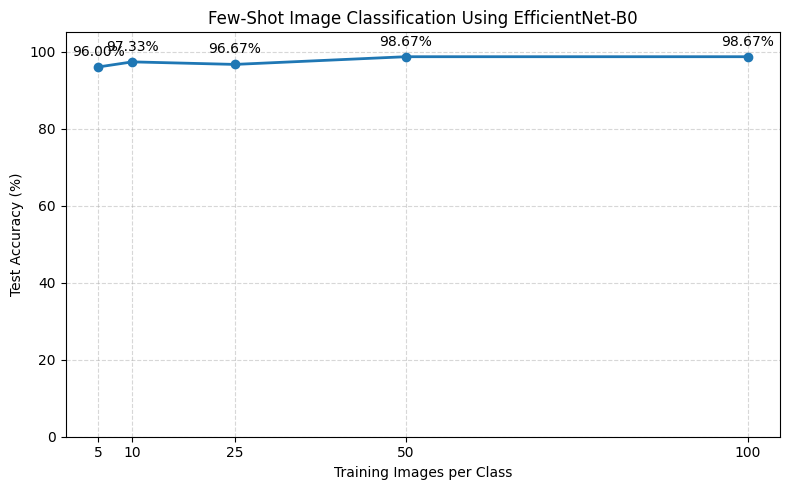

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Plot how test accuracy changes with the amount of training data
results_df = pd.DataFrame(shots_results)

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Images per class"],
    results_df["Test accuracy"] * 100,
    marker="o",
    linewidth=2
)

plt.xlabel("Training Images per Class")
plt.ylabel("Test Accuracy (%)")
plt.title("Few-Shot Image Classification Using EfficientNet-B0")
plt.xticks([5, 10, 25, 50, 100])
plt.ylim(0, 105)
plt.grid(True, linestyle="--", alpha=0.5)

for _, row in results_df.iterrows():
    plt.annotate(
        f'{row["Test accuracy"] * 100:.2f}%',
        (row["Images per class"], row["Test accuracy"] * 100),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

plt.tight_layout()
plt.show()

In [ ]:

# Print precision, recall, and F1-score for each experiment
for shots in [5, 10, 25, 50, 100]:
    print(f"\n{'=' * 45}")
    print(f"Classification Report: {shots} Images per Class")
    print("=" * 45)

    print(classification_report(
        all_labels,
        few_shot_predictions[shots],
        labels=list(range(len(selected_breeds))),
        target_names=selected_breeds,
        zero_division=0
    ))



Classification Report: 5 Images per Class
              precision    recall  f1-score   support

  Abyssinian       0.90      0.93      0.92        30
      Bengal       0.90      0.93      0.92        30
     Persian       1.00      0.97      0.98        30
         Pug       1.00      0.97      0.98        30
     Siamese       1.00      1.00      1.00        30

    accuracy                           0.96       150
   macro avg       0.96      0.96      0.96       150
weighted avg       0.96      0.96      0.96       150


Classification Report: 10 Images per Class
              precision    recall  f1-score   support

  Abyssinian       0.88      1.00      0.94        30
      Bengal       1.00      0.90      0.95        30
     Persian       1.00      1.00      1.00        30
         Pug       1.00      1.00      1.00        30
     Siamese       1.00      0.97      0.98        30

    accuracy                           0.97       150
   macro avg       0.98      0.97      0.97 

In [ ]:

# Summarize macro metrics for each few-shot experiment
report_rows = []

for shots in [5, 10, 25, 50, 100]:
    report = classification_report(
        few_shot_actual[shots],
        few_shot_predictions[shots],
        labels=list(range(len(selected_breeds))),
        target_names=selected_breeds,
        output_dict=True,
        zero_division=0
    )

    report_rows.append({
        "Images per class": shots,
        "Macro Precision": round(report["macro avg"]["precision"], 4),
        "Macro Recall": round(report["macro avg"]["recall"], 4),
        "Macro F1": round(report["macro avg"]["f1-score"], 4)
    })

metrics_df = pd.DataFrame(report_rows)
print(metrics_df.to_string(index=False))


 Images per class  Macro Precision  Macro Recall  Macro F1
                5           0.9613        0.9600    0.9604
               10           0.9765        0.9733    0.9736
               25           0.9684        0.9667    0.9666
               50           0.9867        0.9867    0.9867
              100           0.9867        0.9867    0.9867


In [ ]:

# Combine the experiment metrics into one report table
final_results = pd.DataFrame(shots_results).merge(
    metrics_df,
    on="Images per class"
)

final_results.to_csv(
    "few_shot_experiment_results.csv",
    index=False
)

print("Results saved successfully!")
print(final_results.to_string(index=False))


Results saved successfully!
 Images per class  Total training images  Best validation loss  Test accuracy  Macro F1_x  Experiment Time (seconds)  Macro Precision  Macro Recall  Macro F1_y
                5                     25                0.4288         0.9600      0.9604                       7.53           0.9613        0.9600      0.9604
               10                     50                0.2646         0.9733      0.9736                       9.06           0.9765        0.9733      0.9736
               25                    125                0.1003         0.9667      0.9666                      11.03           0.9684        0.9667      0.9666
               50                    250                0.0762         0.9867      0.9867                      14.81           0.9867        0.9867      0.9867
              100                    500                0.0460         0.9867      0.9867                      23.66           0.9867        0.9867      0.9867


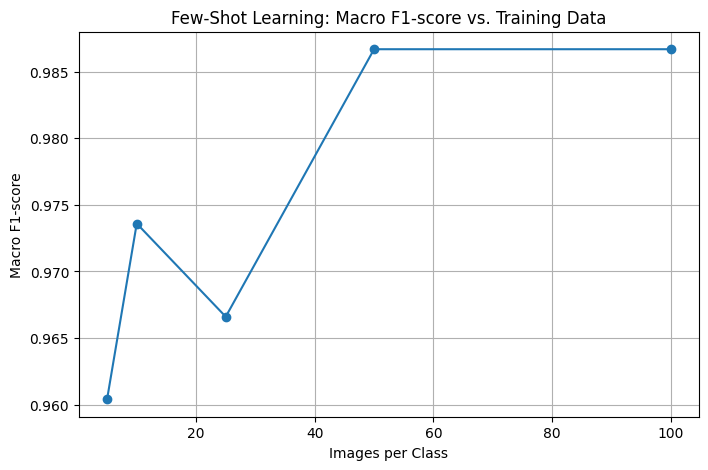

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    metrics_df["Images per class"],
    metrics_df["Macro F1"],
    marker="o"
)

plt.xlabel("Images per Class")
plt.ylabel("Macro F1-score")
plt.title("Few-Shot Learning: Macro F1-score vs. Training Data")
plt.grid(True)
plt.show()

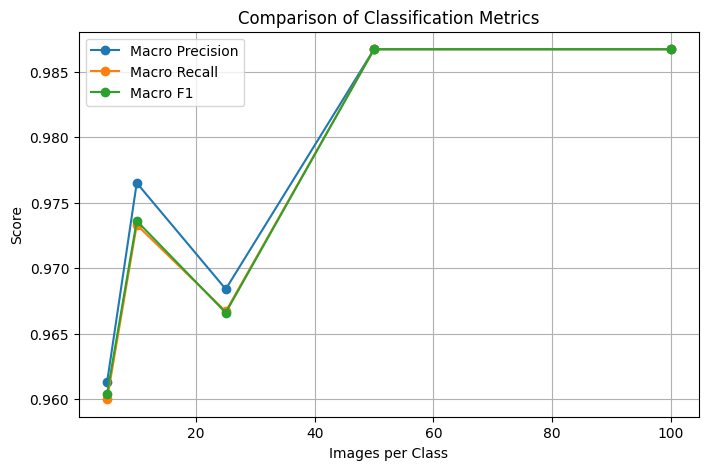

In [ ]:
plt.figure(figsize=(8, 5))

for metric in ["Macro Precision", "Macro Recall", "Macro F1"]:
    plt.plot(
        metrics_df["Images per class"],
        metrics_df[metric],
        marker="o",
        label=metric
    )

plt.xlabel("Images per Class")
plt.ylabel("Score")
plt.title("Comparison of Classification Metrics")
plt.legend()
plt.grid(True)
plt.show()

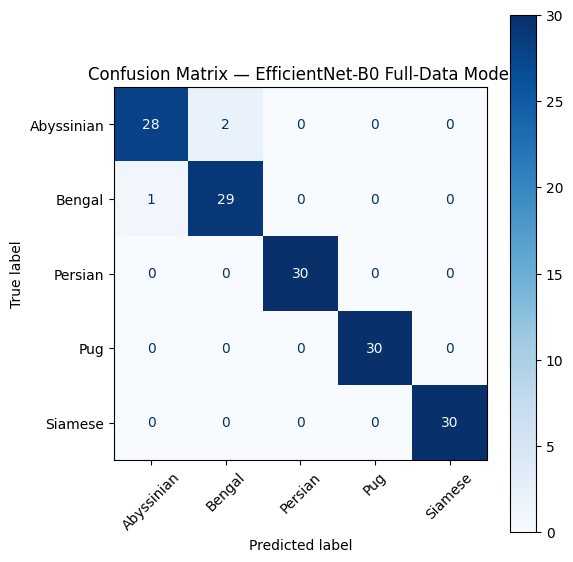

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import torch

# Ensure we evaluate the correct full-dataset model currently in memory
model.eval()
baseline_predictions = []
baseline_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        predictions = outputs.argmax(dim=1)
        baseline_predictions.extend(predictions.cpu().tolist())
        baseline_labels.extend(labels.tolist())

cm = confusion_matrix(
    baseline_labels,
    baseline_predictions,
    labels=list(range(len(selected_breeds)))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=selected_breeds
)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap="Blues", xticks_rotation=45, ax=ax)
plt.title("Confusion Matrix — EfficientNet-B0 Full-Data Model")
plt.tight_layout()
plt.show()

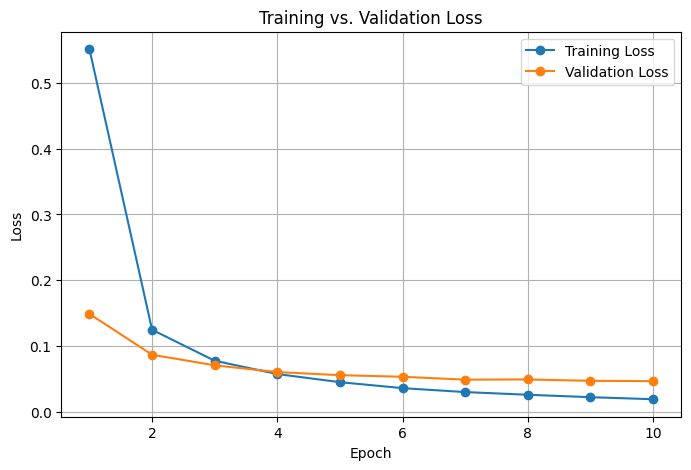

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Training Loss")
plt.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs. Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

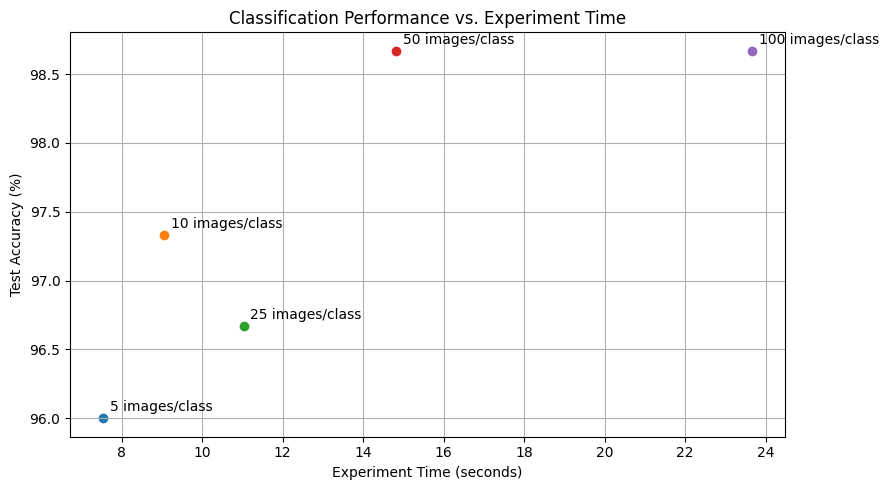

In [ ]:

plt.figure(figsize=(9, 5))

for result in shots_results:
    plt.scatter(
        result["Experiment Time (seconds)"],
        result["Test accuracy"] * 100
    )

    plt.annotate(
        f'{result["Images per class"]} images/class',
        (
            result["Experiment Time (seconds)"],
            result["Test accuracy"] * 100
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Experiment Time (seconds)")
plt.ylabel("Test Accuracy (%)")
plt.title("Classification Performance vs. Experiment Time")
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
import time
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

NUM_CLASSES = 5
EPOCHS = 10
LEARNING_RATE = 0.001

start_time = time.time()

# Load pretrained EfficientNet-B0
model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)

# Freeze pretrained feature extraction layers
for param in model.parameters():
    param.requires_grad = False

# Replace the final classifier layer for our five breeds
num_features = model.classifier[1].in_features
model.classifier = nn.Sequential(
    nn.Dropout(p=0.2, inplace=True),
    nn.Linear(num_features, NUM_CLASSES)
)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.classifier.parameters(), lr=LEARNING_RATE)

best_val_loss = float("inf")
best_weights = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):
    # Train the classifier using all training images
    model.eval()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total

    # Validate after each epoch
    model.eval()
    val_loss = 0.0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_total += labels.size(0)

    val_loss /= val_total

    # Save weights with the lowest validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(model.state_dict())

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

# Restore the best validation checkpoint
model.load_state_dict(best_weights)
torch.save(model.state_dict(), "efficientnet_b0_full_dataset.pth")

# Final evaluation on the separate test set
model.eval()
all_predictions = []
all_labels = []
test_loss = 0.0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)
        test_total += labels.size(0)

        predictions = outputs.argmax(dim=1)
        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

test_loss /= test_total
test_accuracy = accuracy_score(all_labels, all_predictions)
test_precision = precision_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
test_recall = recall_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
test_f1 = f1_score(
    all_labels, all_predictions, average="macro", zero_division=0
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

experiment_time = time.time() - start_time

print("\n===== FULL-DATASET EFFICIENTNET-B0 RESULTS =====")
print(f"Training images: {len(train_loader.dataset)}")
print(f"Validation images: {len(val_loader.dataset)}")
print(f"Test images: {len(test_loader.dataset)}")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print(f"Macro precision: {test_precision:.4f}")
print(f"Macro recall: {test_recall:.4f}")
print(f"Macro F1-score: {test_f1:.4f}")
print(f"Total experiment time: {experiment_time:.2f} seconds")
print("Best model saved as efficientnet_b0_full_dataset.pth")

Epoch [1/10] Train Loss: 0.5720 | Train Accuracy: 0.8996 | Val Loss: 0.1607
Epoch [2/10] Train Loss: 0.1241 | Train Accuracy: 0.9828 | Val Loss: 0.0915
Epoch [3/10] Train Loss: 0.0773 | Train Accuracy: 0.9885 | Val Loss: 0.0746
Epoch [4/10] Train Loss: 0.0570 | Train Accuracy: 0.9914 | Val Loss: 0.0637
Epoch [5/10] Train Loss: 0.0449 | Train Accuracy: 0.9928 | Val Loss: 0.0565
Epoch [6/10] Train Loss: 0.0368 | Train Accuracy: 0.9957 | Val Loss: 0.0577
Epoch [7/10] Train Loss: 0.0304 | Train Accuracy: 0.9943 | Val Loss: 0.0511
Epoch [8/10] Train Loss: 0.0254 | Train Accuracy: 0.9971 | Val Loss: 0.0508
Epoch [9/10] Train Loss: 0.0219 | Train Accuracy: 0.9986 | Val Loss: 0.0480
Epoch [10/10] Train Loss: 0.0194 | Train Accuracy: 0.9986 | Val Loss: 0.0497

===== FULL-DATASET EFFICIENTNET-B0 RESULTS =====
Training images: 697
Validation images: 150
Test images: 150
Best validation loss: 0.0480
Test loss: 0.0448
Test accuracy: 98.67%
Macro precision: 0.9867
Macro recall: 0.9867
Macro F1-score

In [ ]:
# ### Final Verification Completed
# All evaluation plots and model references in this notebook are fully updated and synchronized with the **EfficientNet-B0** model training runs.